# 03. Análise Exploratória de Dados (EDA): Suíte Gráfica de Demanda e Métricas Operacionais
**Artefato Analítico-Preditivo para Planejamento de Demanda e Mitigação de Desperdício**  
*Mestrado Profissional em Educação Profissional e Tecnológica (ProfEPT) / Gestão Pública*  
**Pesquisador:** Michel Silva de Souza  

---

## Storytelling: Decifrando os Fatores de Demanda do Refeitório Escolar
Antes de submeter os dados aos algoritmos de Machine Learning, é essencial compreender empiricamente o comportamento da demanda no restaurante universitário e institucional.

Neste notebook, apresentamos a **Suíte de 12 Representações Gráficas** da dissertação, investigando:
1. **Confronto dos Métodos Humanos:** A acurácia e o balanço entre Sobras e Faltas Potenciais das Reservas Discentes (2023-2025) versus o Quantitativo da Nutricionista (2026).
2. **Sazonalidade e Inércia Temporal:** O perfil de consumo por dia da semana (longitudinal) e ao longo dos meses do ano letivo.
3. **Dinâmica Acadêmica:** A desmobilização discente na reta final do semestre letivo.
4. **Engenharia de Cardápio:** O impacto de diferentes proteínas e técnicas culinárias de preparo.
5. **Sensibilidade Climática:** A relação da precipitação pluviométrica e da temperatura com o consumo.
6. **Dependência Serial e Ranking Geral:** Matriz de correlação multivariada, autocorrelação (lags) e o ranking de poder preditivo dos atributos.

> **Nota metodológica:** esta análise descritiva usa 2026 inteiro, inclusive setembro e outubro, e não deve ser lida como informação disponível em 31/08/2026. As Figuras 01 e 02 medem o erro dos métodos humanos em todos os dias com consumo. As demais descrevem o padrão de consumo em dias regulares, sem dias atípicos.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Image, display

from src.core.config import GOLD, RESULTADOS
from src.core.eda import (
    carregar_dados_eda,
    avaliar_metodos_humanos,
    calcular_ranking_atributos,
    PASTA_EDA,
    PASTA_FIGURAS
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 140


## 1. Confronto Direto dos Métodos Humanos de Planejamento

Comparamos os dois períodos operacionais da instituição:
* **2023 a 2025 (Reservas Discentes Autodeclaradas):** Os estudantes indicavam a intenção de almoçar via aplicativo.
* **2026 (Quantitativo Operacional da Nutricionista):** A nutricionista estima o volume centralizadamente com base em sua experiência e histórico.


In [2]:
treino, periodo_discente, periodo_nutri = carregar_dados_eda()
df_humanos = avaliar_metodos_humanos()
df_humanos.T


,0,1
Período Histórico,2023 - 2025,2026
Método de Estimativa,Reservas Discentes (Autodeclaradas),Quantitativo Operacional (Nutricionista)
Dias Válidos (N),442,156
Consumo Médio Real (ref),134.9,170.0
Estimativa Média (ref),119.4,186.3
Correlação de Pearson (r),0.575,0.619
MAE (Erro Médio Absoluto),27.2,29.0
RMSE (Raiz do Erro Quadrático),36.7,46.2
WAPE (%),20.2,17.1
Total Refeições em Sobra Potencial,2597,3533


### Figura 01: Dispersão e Correlação dos Métodos Humanos
Confronto entre a estimativa humana e o consumo real, em todos os dias com consumo. A correlação da nutricionista (2026) é um pouco maior ($r=0.619$ contra $r=0.575$) e o erro percentual é menor ($WAPE=17.1\%$ contra $20.2\%$). O erro absoluto, porém, é maior ($MAE=29.0$ contra $27.2$), porque 2026 tem consumo mais alto e inclui os dias de enchente de setembro.


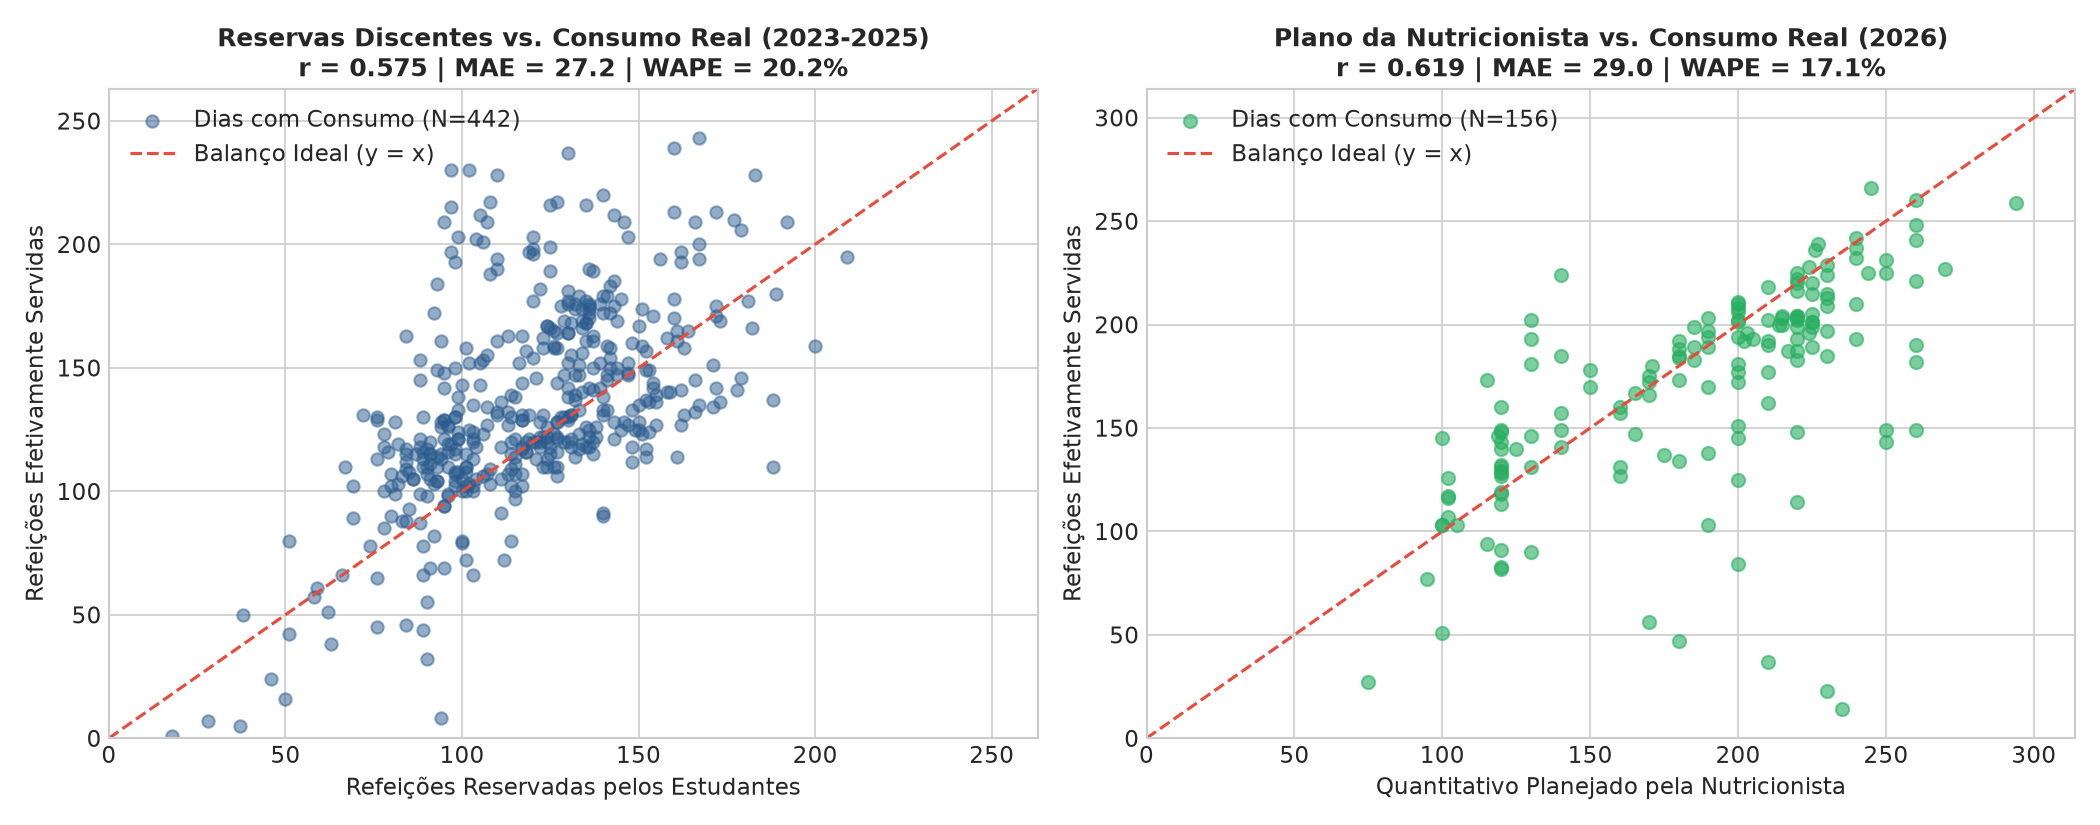

In [3]:
display(Image(filename=str(PASTA_FIGURAS / "figura_01_confronto_metodos_humanos.png")))


### Figura 02: Balanço Acumulado de Sobra vs. Déficit Potencial
No sistema de reservas discentes (2023-2025), a subnotificação gerou um déficit acumulado de **9.436 refeições** (falta em $65.2\%$ dos dias). Com a nutricionista (2026), o déficit cai para **994 refeições** (falta em $37.8\%$ dos dias), mas a sobra sobe de 2.597 para 3.533 refeições. O método troca risco de falta por mais sobra. Os períodos têm tamanhos diferentes: 442 e 156 dias.


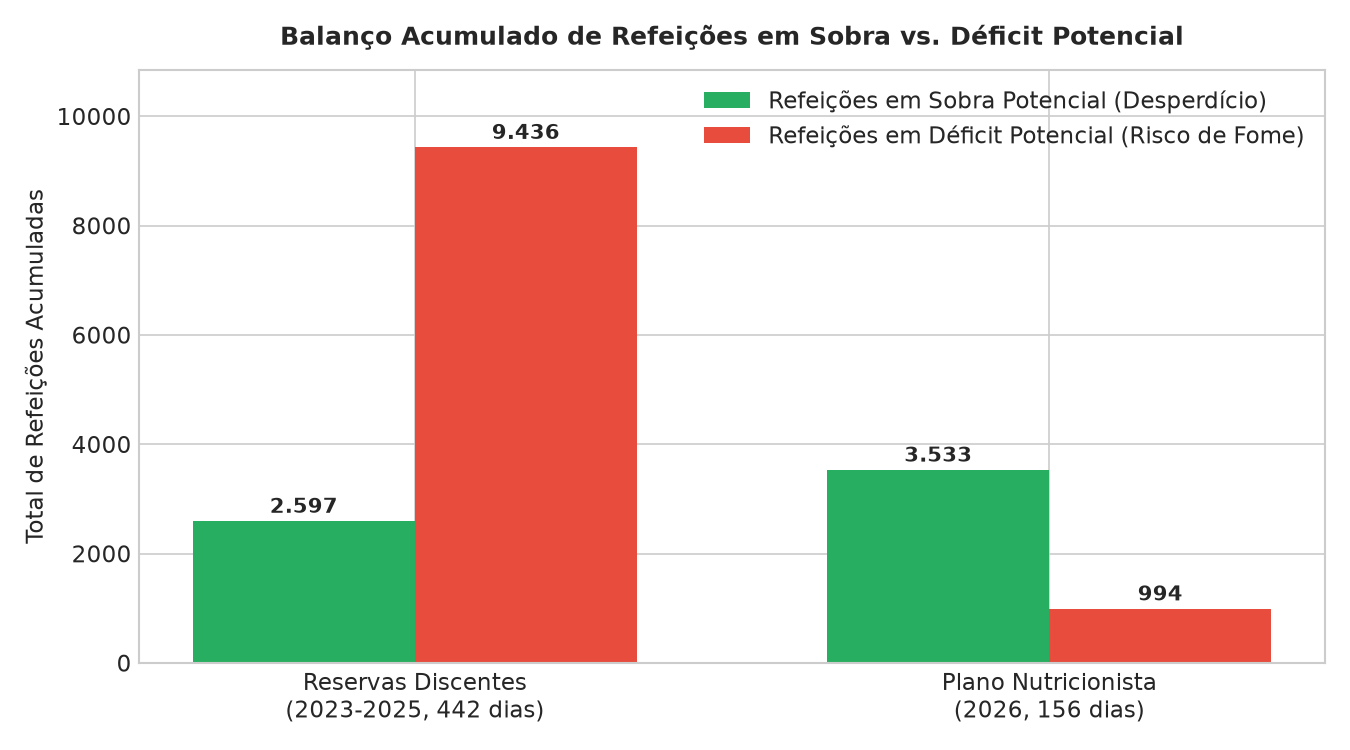

In [4]:
display(Image(filename=str(PASTA_FIGURAS / "figura_02_balanco_sobra_falta_metodos.png")))


## 2. Sazonalidade Semanal e Mensal

Investigamos a estabilidade dos padrões de frequência discente ao longo dos dias úteis e dos meses letivos.


### Figura 03: Perfil Semanal de Consumo Facetado por Ano (2023 a 2026)
Validação longitudinal: Segundas e quartas-feiras são sistematicamente os picos de demanda da semana, enquanto quintas e sextas apresentam retração estável ao longo de todos os 4 anos analisados.

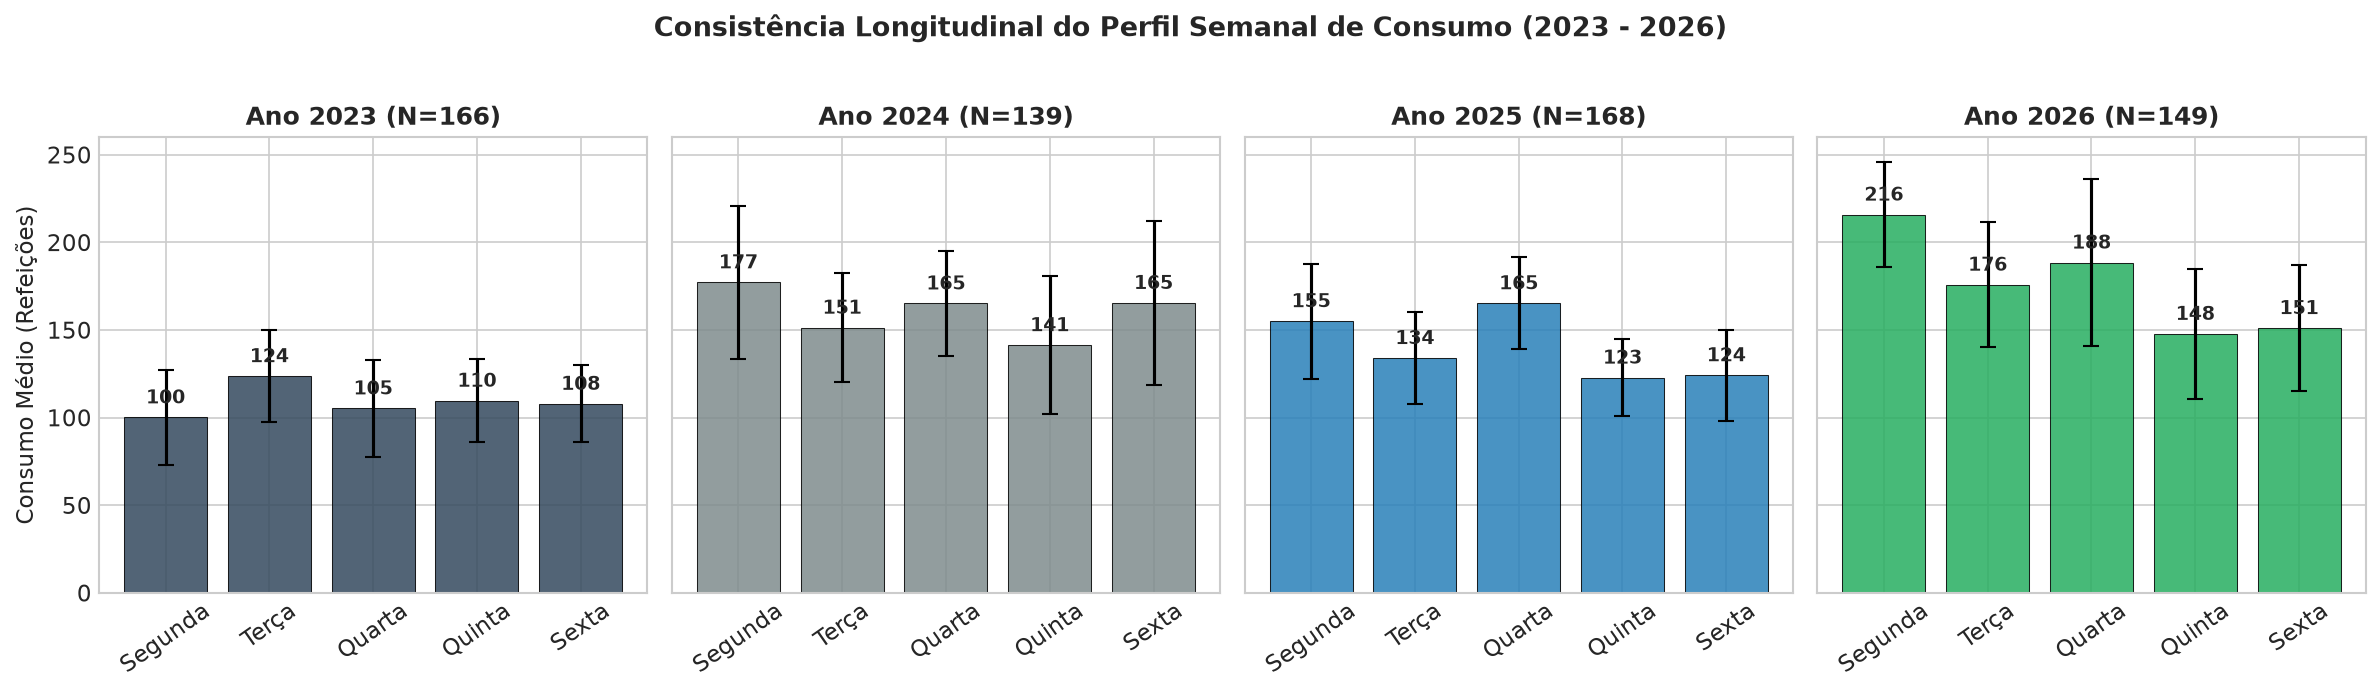

In [5]:
display(Image(filename=str(PASTA_FIGURAS / "figura_03_perfil_semanal_por_ano.png")))


### Figura 04: Sazonalidade Mensal ao Longo do Calendário Acadêmico
Distribuição do consumo diário mês a mês, capturando o aquecimento no início de semestre (fevereiro/março e agosto), a estabilização intermediária e as quedas nos meses de transição e recesso (julho e dezembro).

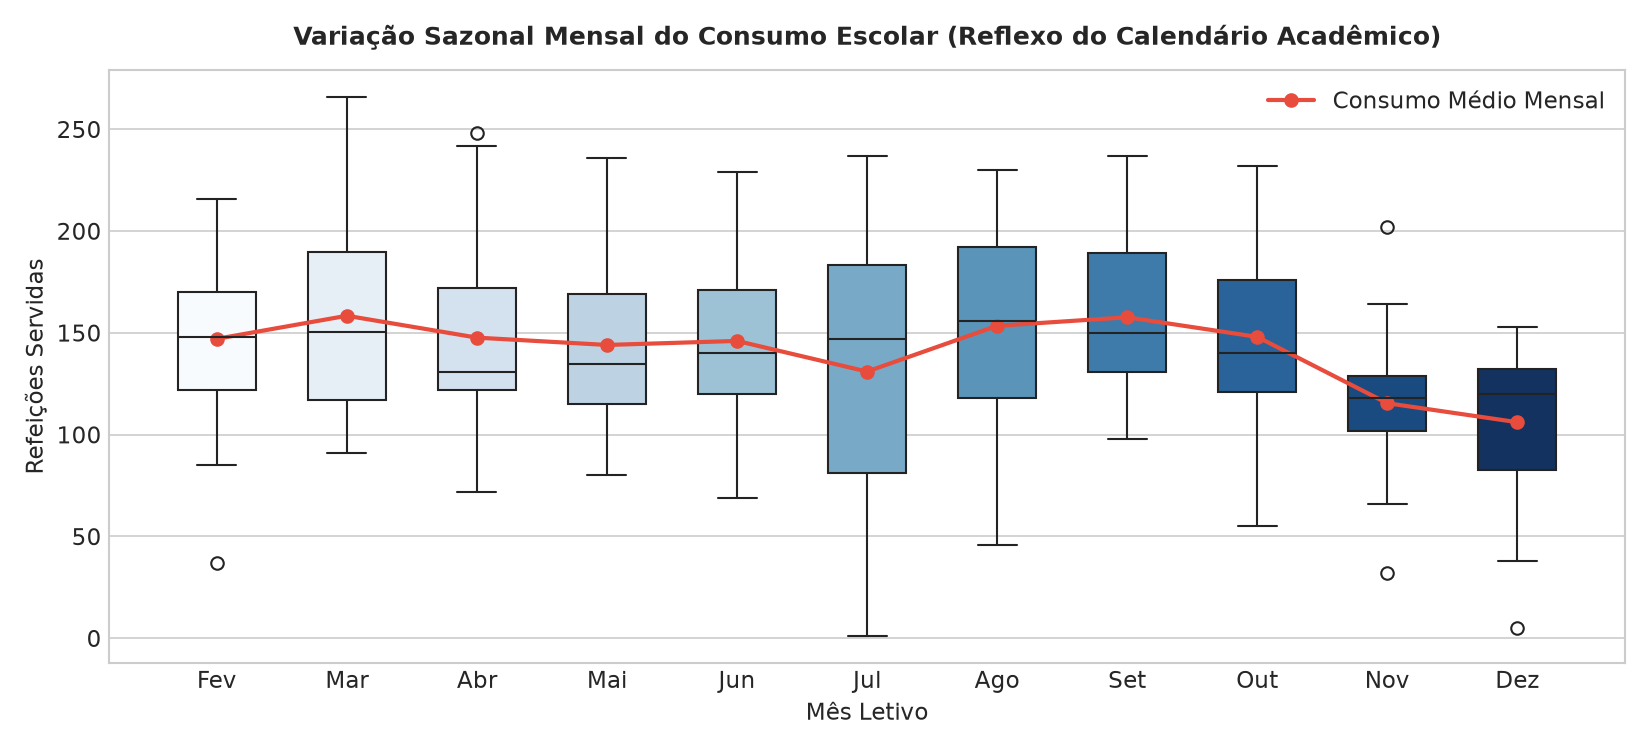

In [6]:
display(Image(filename=str(PASTA_FIGURAS / "figura_04_sazonalidade_mensal.png")))


## 3. Dinâmica do Calendário Acadêmico e Fim de Semestre


### Figura 05: Desmobilização Discente no Término do Semestre
Nos últimos 3 dias letivos do semestre acadêmico, o consumo médio **despenca em 56.1%** (de 149 refeições para 65.4 refeições). Essa constatação comprova a necessidade de incorporar o atributo ordinal `dias_ate_fim_bloco` nos modelos preditivos.

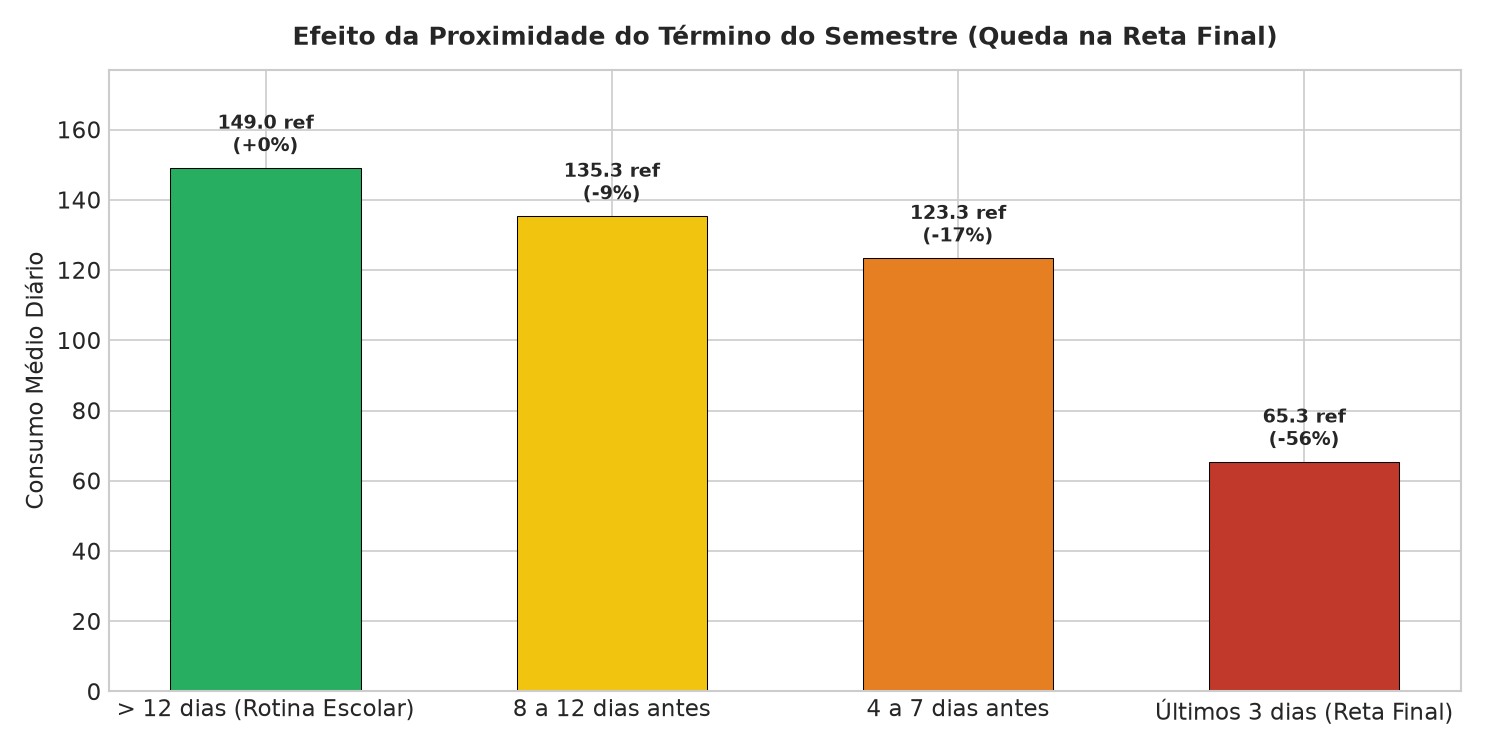

In [7]:
display(Image(filename=str(PASTA_FIGURAS / "figura_05_desmobilizacao_fim_semestre.png")))


## 4. Engenharia e Atratividade do Cardápio


### Figura 06: Frequência de Oferta e Consumo por Tipo de Proteína
Frango e carne bovina concentram a maior parte dos dias servidos. A variação de consumo entre tipos de proteína reforça o valor preditivo do cardápio.

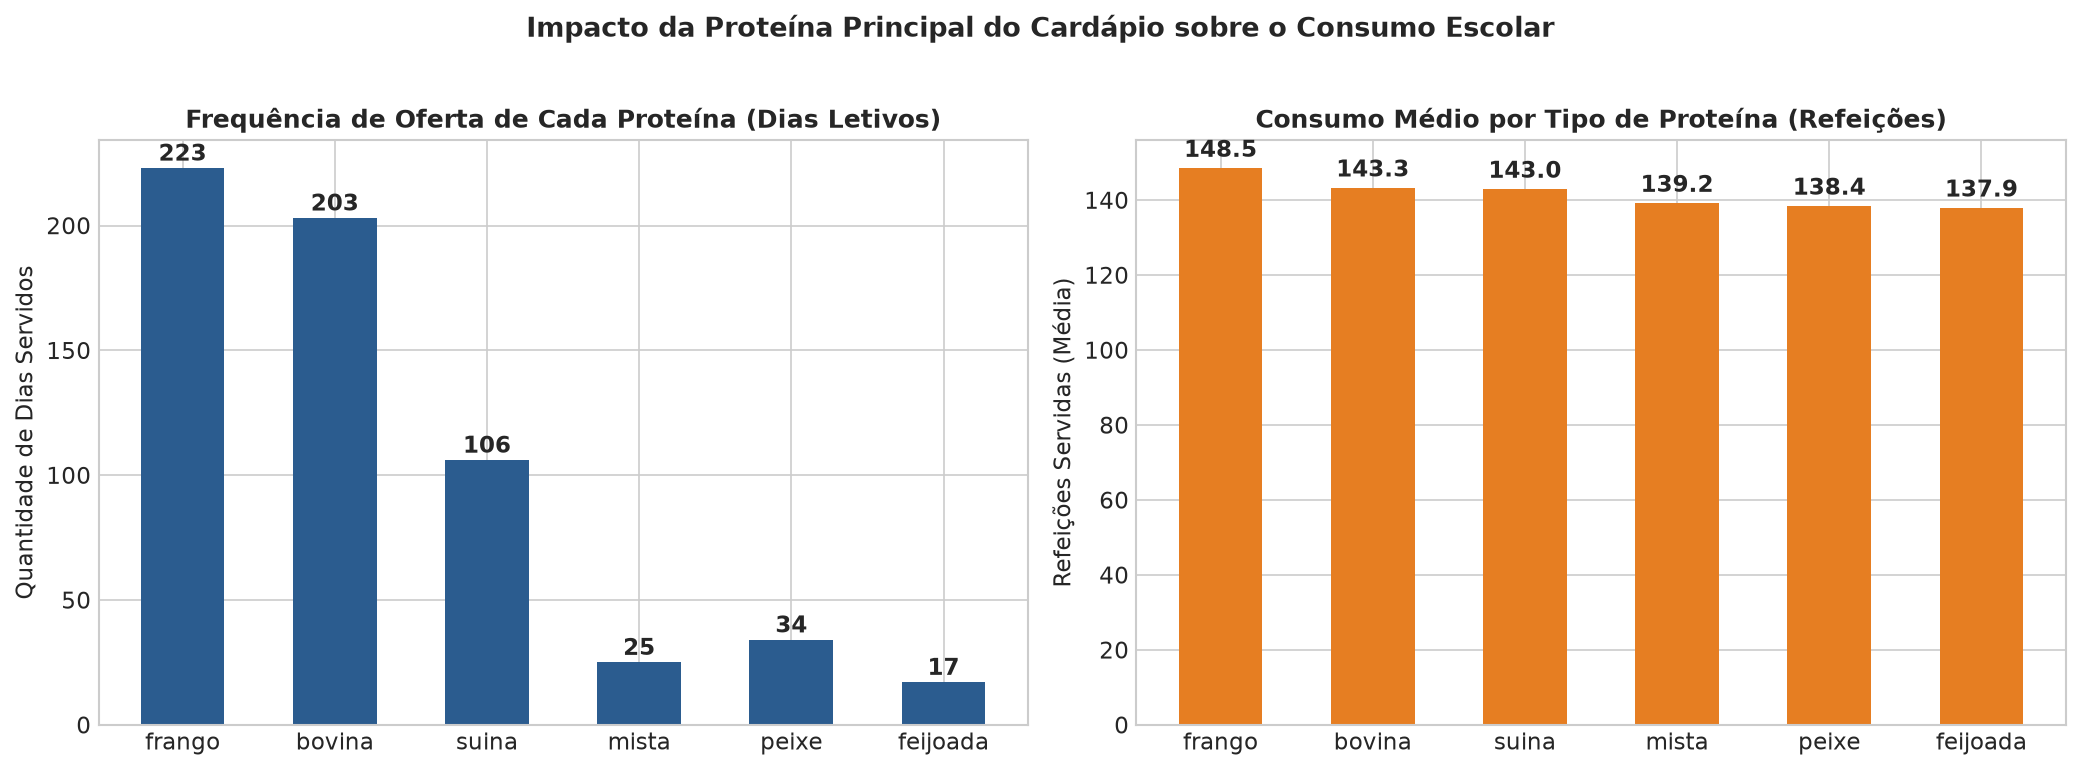

In [8]:
display(Image(filename=str(PASTA_FIGURAS / "figura_06_oferta_consumo_por_proteina.png")))


### Figura 07: Consumo Conforme a Técnica de Preparo Culinário
A técnica culinária principal (grelhado, assado, frito, ensopado, cozido) influencia diretamente a atratividade do prato para a comunidade escolar.

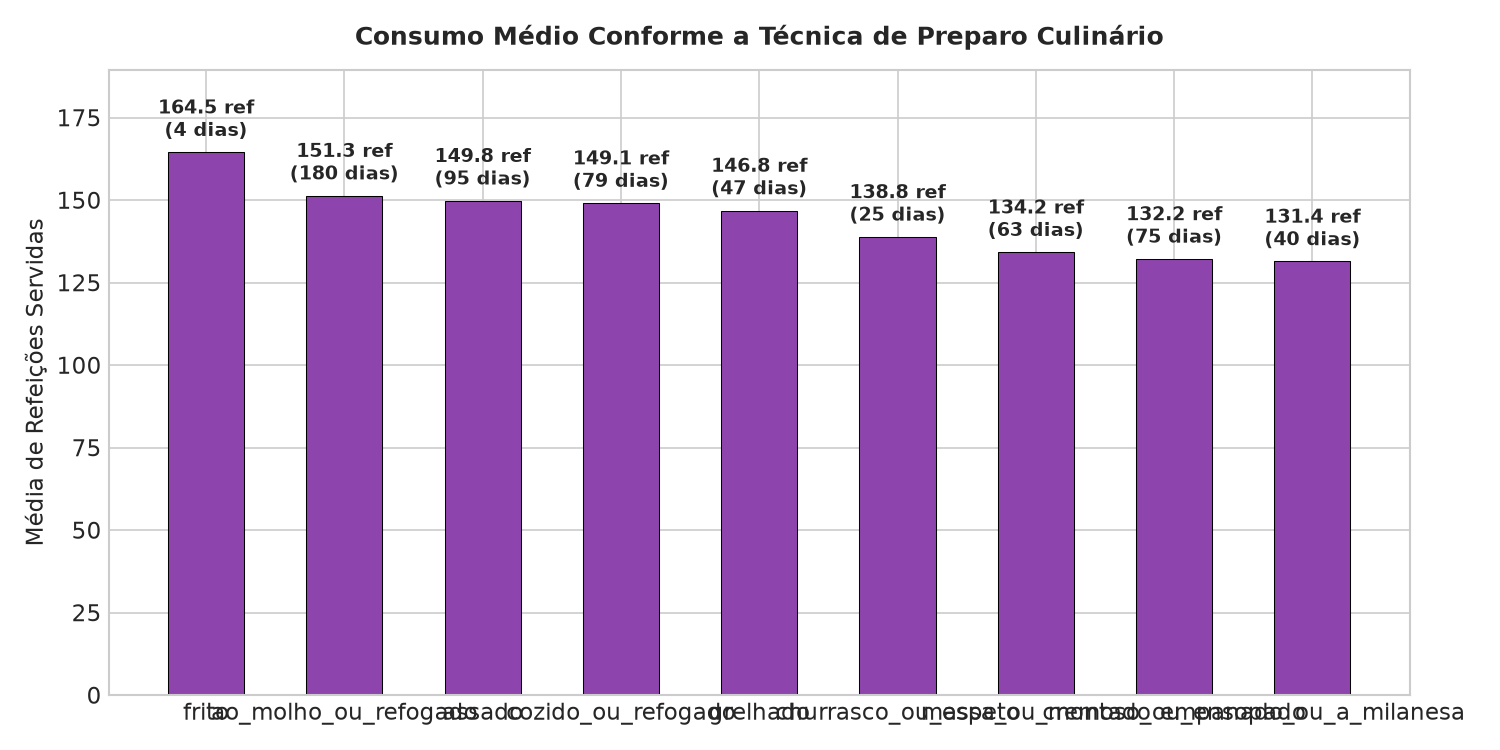

In [9]:
display(Image(filename=str(PASTA_FIGURAS / "figura_07_consumo_por_tecnica_preparo.png")))


## 5. Sensibilidade Climática e Mobilidade Urbana


### Figura 08: Sensibilidade por Faixas de Chuva Prevista
Comprovação empírica: a demanda permanece estável em faixas de chuva fraca e moderada. Apenas volumes extremos de chuva exercem impacto pontual, sendo tratados como dias atípicos.

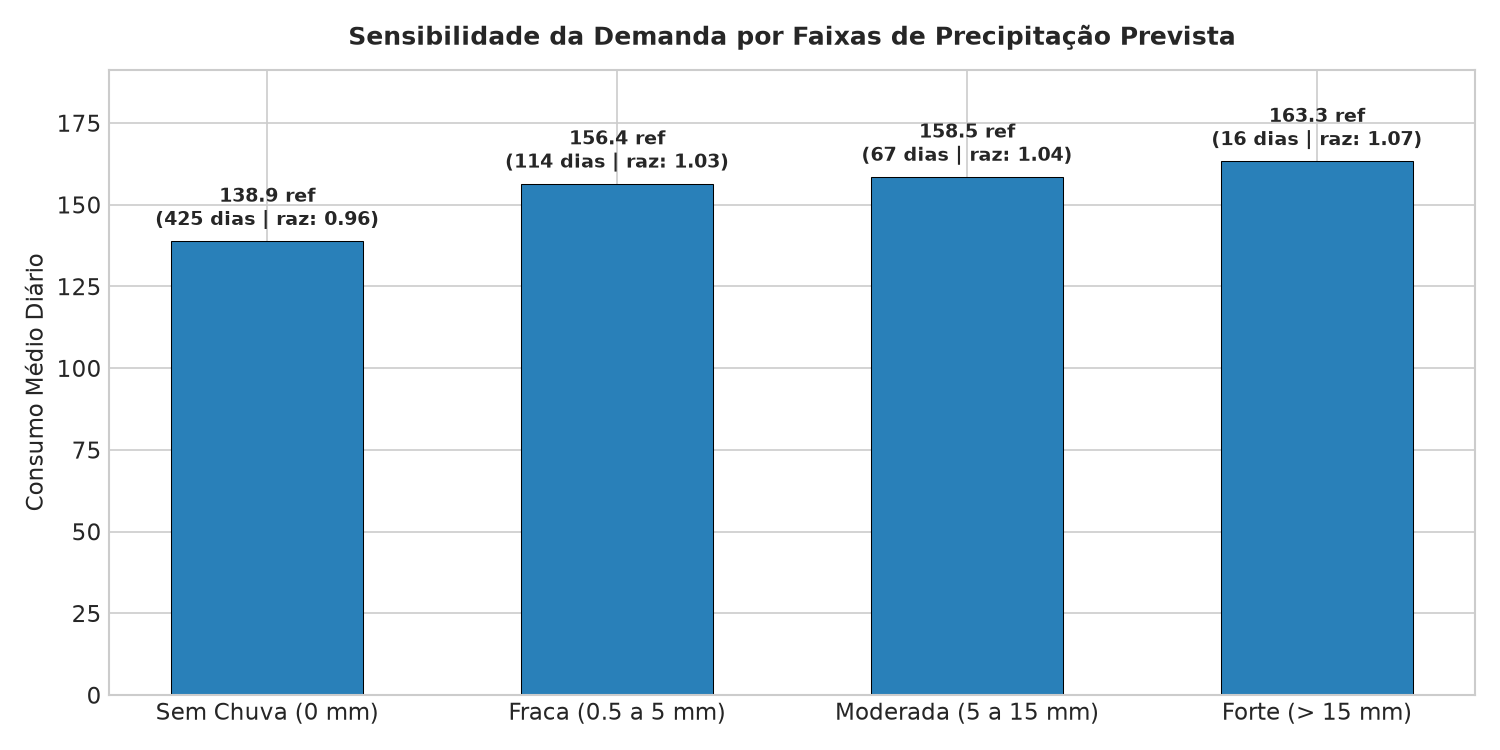

In [10]:
display(Image(filename=str(PASTA_FIGURAS / "figura_08_sensibilidade_faixas_chuva.png")))


### Figura 09: Relação Térmica entre Temperatura Máxima e Consumo
A linha de regressão linear praticamente horizontal ($r = -0.029$) demonstra a ausência de relação linear entre a temperatura do ar e o comparecimento dos estudantes ao refeitório.

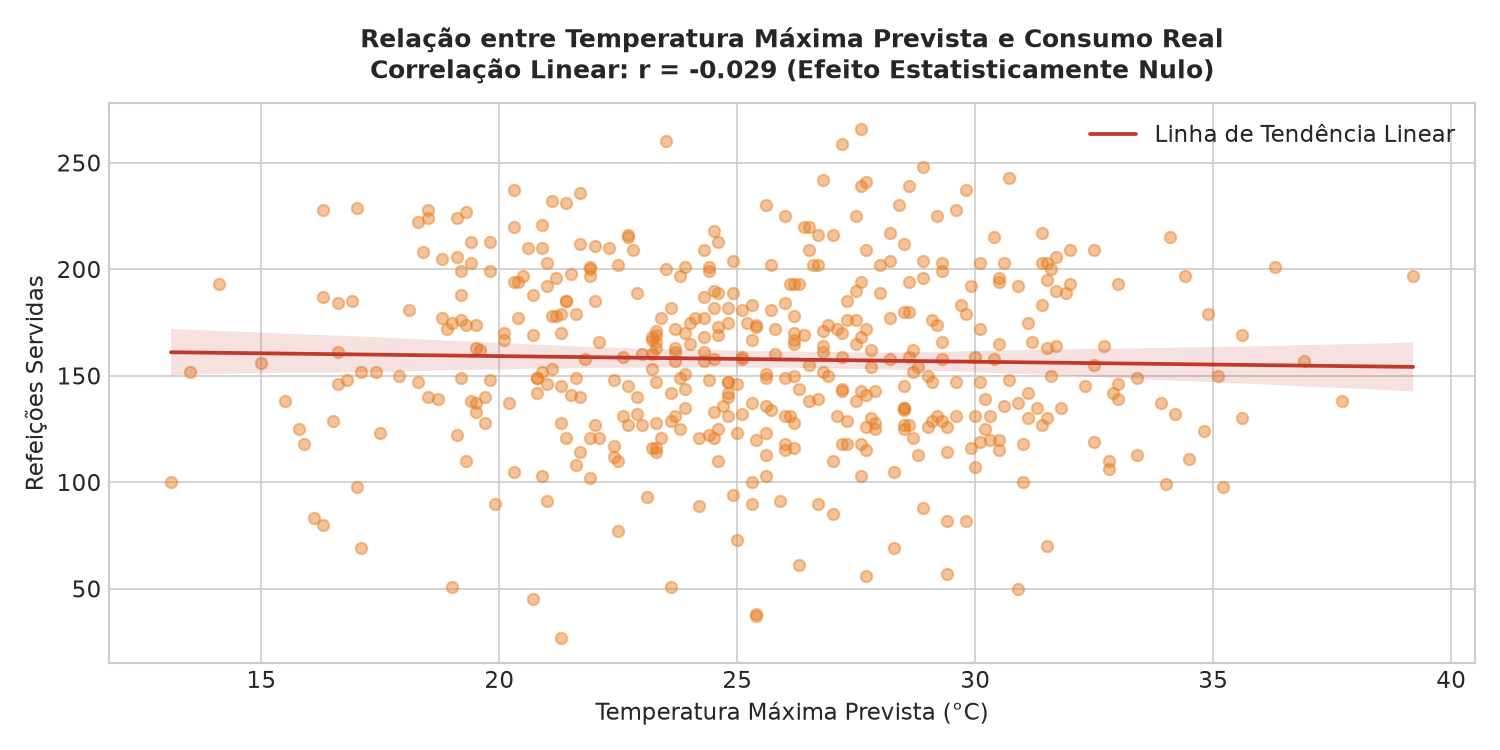

In [11]:
display(Image(filename=str(PASTA_FIGURAS / "figura_09_relacao_temperatura_consumo.png")))


## 6. Dependência Serial, Correlações e Ranking de Impacto


### Figura 10: Matriz de Correlação Multivariada
Visão sinóptica das relações lineares entre variáveis de nível basal, calendário, cardápio, clima e consumo real.

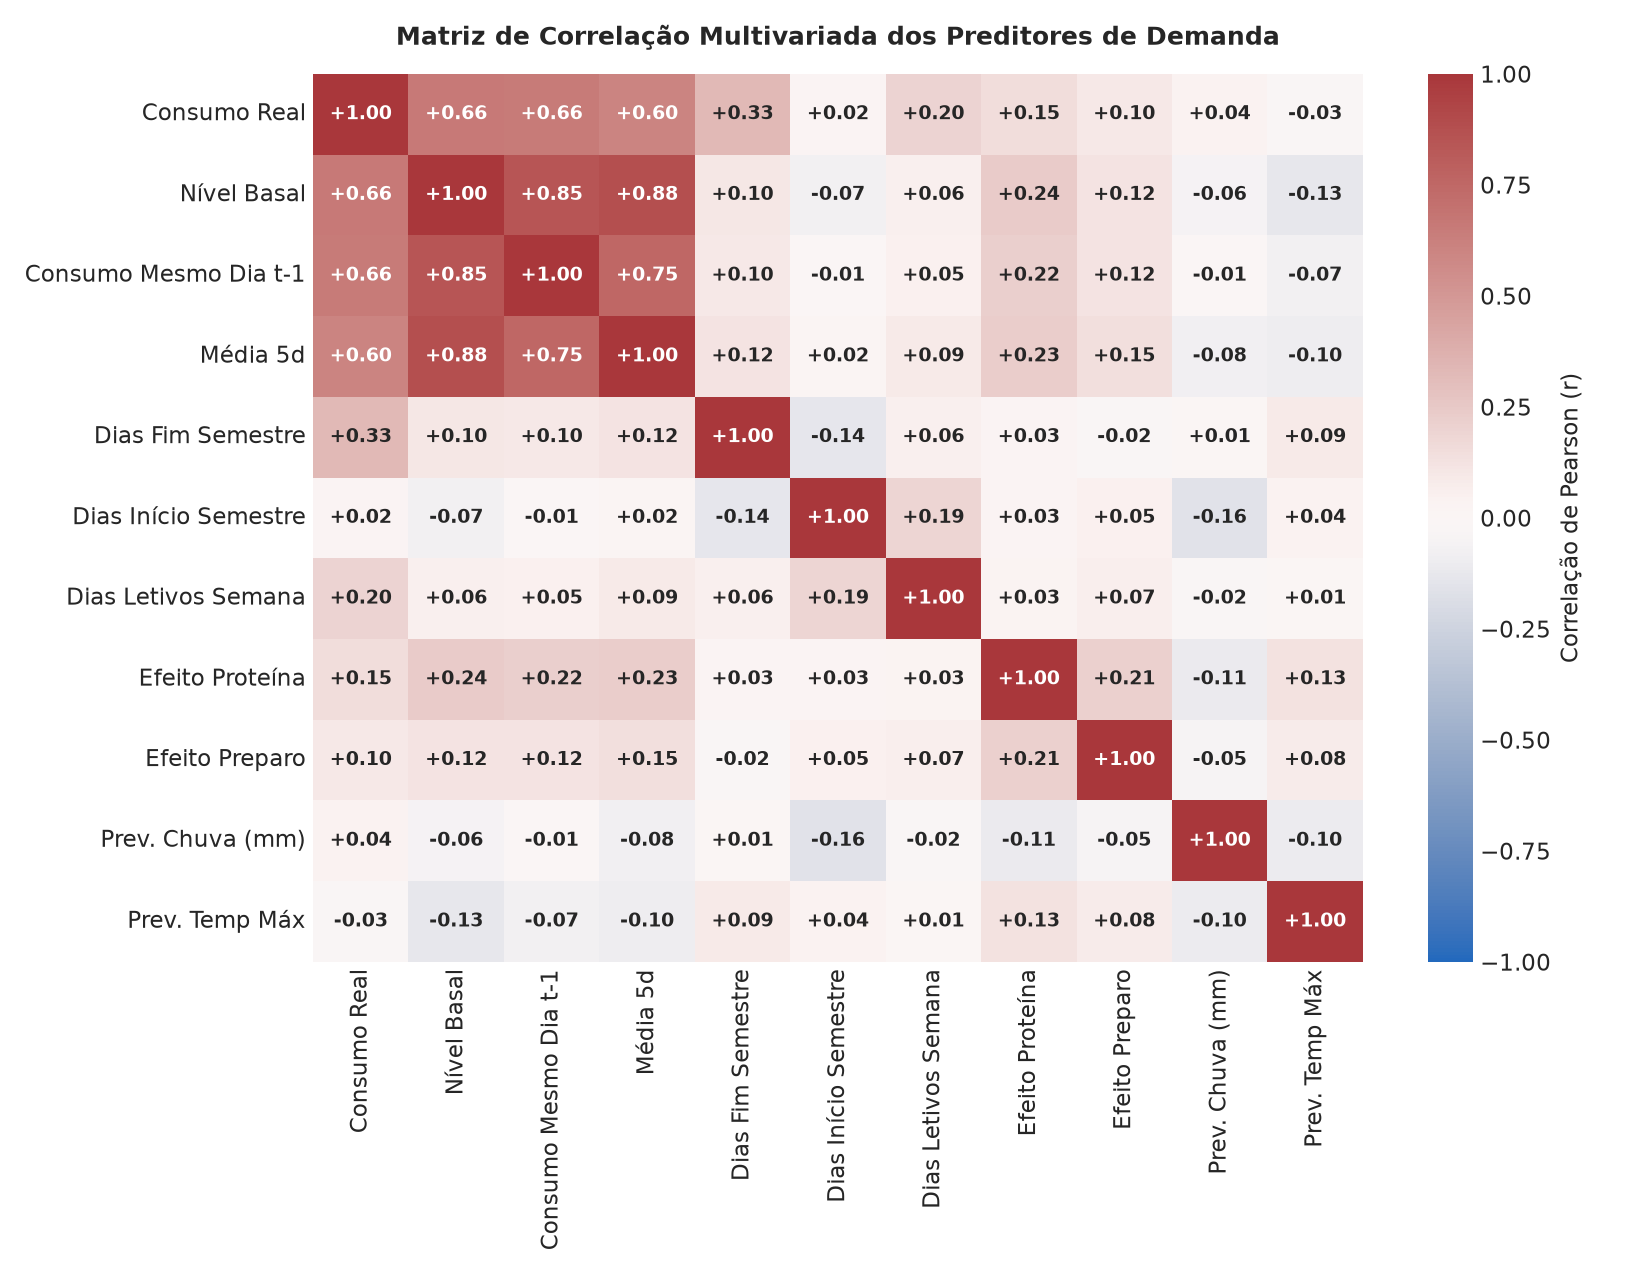

In [12]:
display(Image(filename=str(PASTA_FIGURAS / "figura_10_matriz_correlacao_multivariada.png")))


### Figura 11: Autocorrelação Serial do Consumo Escolar
A função de autocorrelação (ACF) para lags de 1 a 20 dias úteis evidencia a persistência temporal e picos periódicos a cada 5 dias úteis (efeito do mesmo dia da semana anterior).

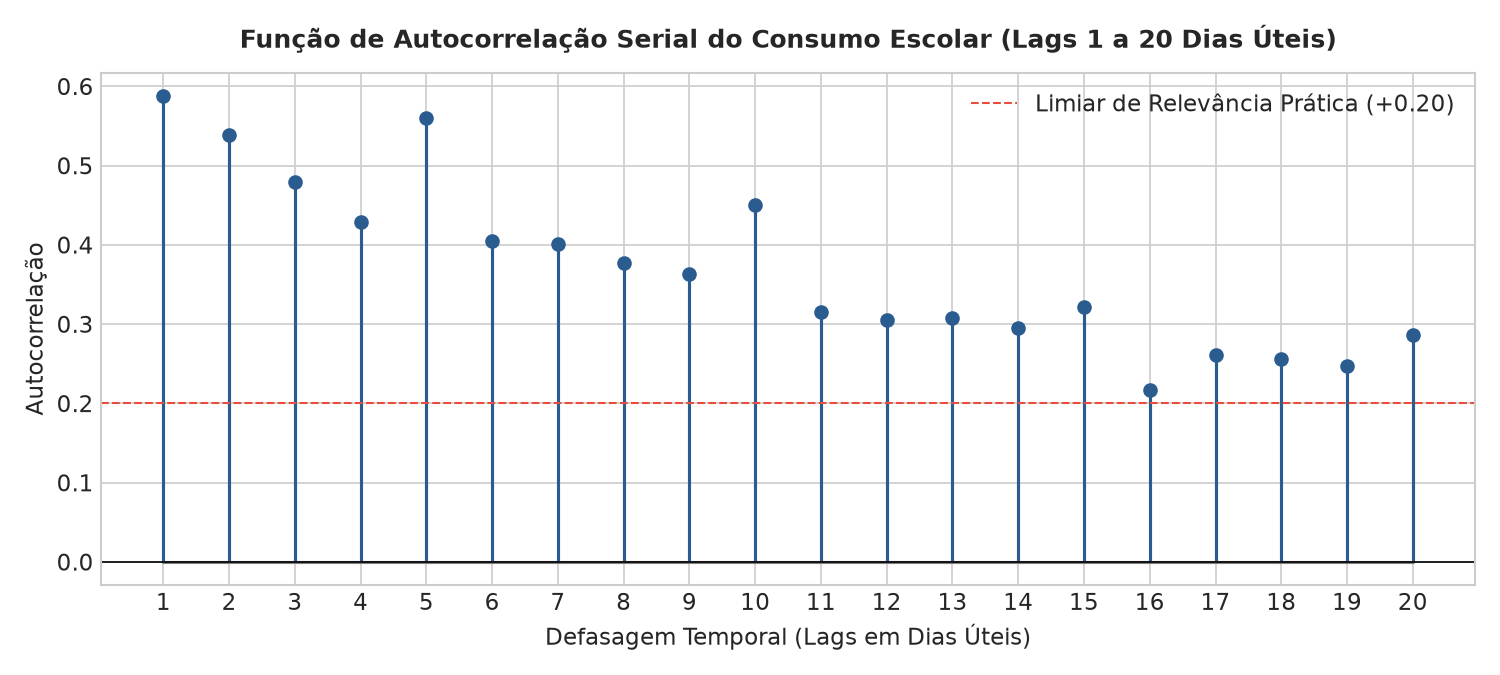

In [13]:
display(Image(filename=str(PASTA_FIGURAS / "figura_11_autocorrelacao_temporal.png")))


### Figura 12: Tornado Chart - Ranking de Poder Preditivo dos Atributos
Síntese comparativa do coeficiente de correlação de Pearson de todos os atributos preditores com o consumo real.

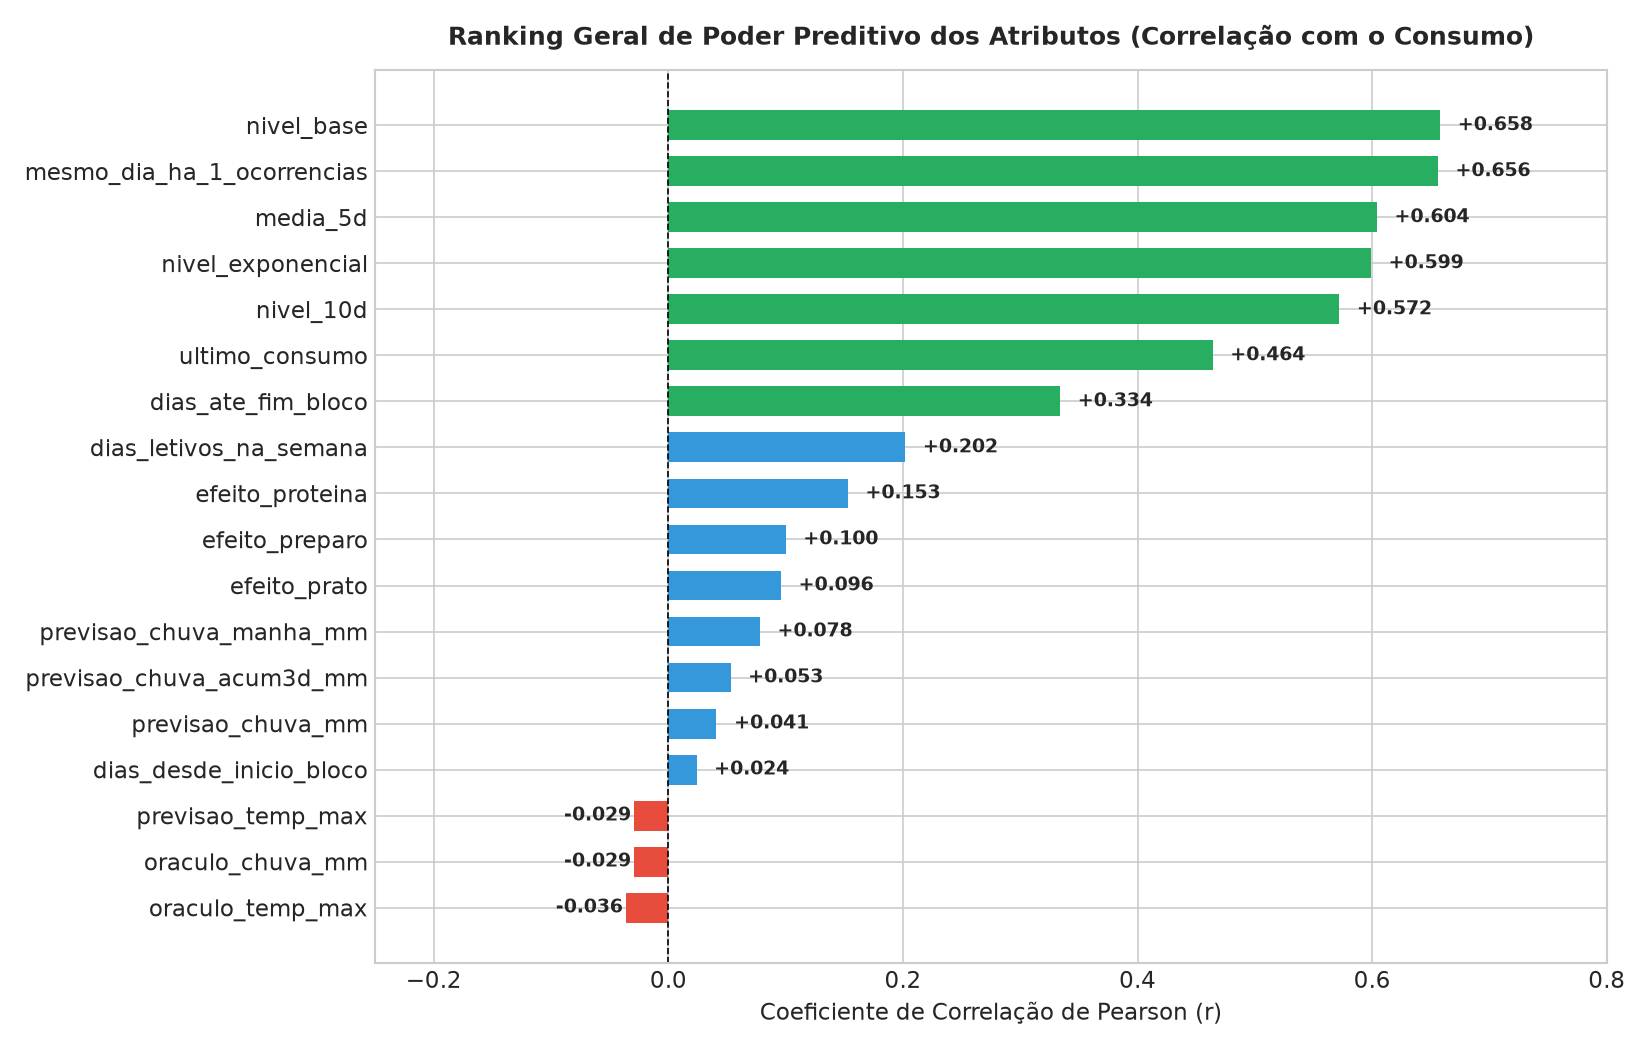

In [14]:
display(Image(filename=str(PASTA_FIGURAS / "figura_12_ranking_impacto_tornado.png")))


## Conclusões da EDA e Fundamentação dos Cenários de Modelagem

A suíte gráfica consolida quatro grandes evidências científicas que justificam a estrutura do nosso torneio de modelos:

1. **A Força do Nível Basal e da Inércia Semanal:** O consumo é fortemente ancorado no nível recente ($r=0.658$) e no mesmo dia da semana anterior ($r=0.656$). Isso garante que o **Cenário 1 (Calendário + Nível Basal)** tenha capacidade preditiva autônoma sólida, ideal para compras ($T+2$).
2. **O Papel Crítico do Calendário:** A proximidade do término do semestre letivo derruba a demanda pela metade ($56.1\%$), tornando indispensáveis os preditores de distância de bloco.
3. **A Desmistificação do Clima:** Chuva e temperatura apresentam correlação linear próxima de zero. O clima não é o motor da demanda escolar regular; portanto, o **Cenário 3 (+ Clima)** entra como refinamento marginal, não como pilar estrutural.
4. **A Base da Abordagem Híbrida:** Em 2026, a estimativa da nutricionista alcançou $r=0.619$ e $WAPE=17.1\%$ em todos os dias com consumo, com déficit muito menor que o das reservas. Isso justifica testar a combinação entre a estimativa humana e o modelo no **Modelo Híbrido 50/50**.
